In [3]:
# Does the measured Z mass depend on how and where the muons were detected?
# Data: CMS 2011 "Z to two muons" (CERN Open Data record 5208), Zmumu.csv
# Idea: the Z mass is a fixed number, so its measured peak position should NOT change
# with muon eta, phi, pT or charge. Any trend points to a detector effect.

# %% Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


In [4]:
df = pd.read_csv("Zmumu.csv")
MU = 0.10566  # muon mass [GeV]

# 4-vectors of the two muons
px1, py1, pz1 = df.pt1 * np.cos(df.phi1), df.pt1 * np.sin(df.phi1), df.pt1 * np.sinh(df.eta1)
px2, py2, pz2 = df.pt2 * np.cos(df.phi2), df.pt2 * np.sin(df.phi2), df.pt2 * np.sinh(df.eta2)
e1 = np.sqrt(px1**2 + py1**2 + pz1**2 + MU**2)
e2 = np.sqrt(px2**2 + py2**2 + pz2**2 + MU**2)
df["mass"] = np.sqrt(np.maximum((e1 + e2)**2 - (px1 + px2)**2 - (py1 + py2)**2 - (pz1 + pz2)**2, 0))

# Keep only opposite-charge pairs (a real Z gives one mu+ and one mu-)
df = df[df.Q1 * df.Q2 < 0].copy()
print("Events after opposite-charge cut:", len(df))

Events after opposite-charge cut: 9664


In [5]:
# %% 2. Re-organise by charge: variables of the mu+ and of the mu- in each event
plus_is_1 = df.Q1 > 0
df["pt_plus"]  = np.where(plus_is_1, df.pt1,  df.pt2)
df["pt_minus"] = np.where(plus_is_1, df.pt2,  df.pt1)
df["eta_plus"]  = np.where(plus_is_1, df.eta1, df.eta2)
df["eta_minus"] = np.where(plus_is_1, df.eta2, df.eta1)
df["phi_plus"]  = np.where(plus_is_1, df.phi1, df.phi2)
df["phi_minus"] = np.where(plus_is_1, df.phi2, df.phi1)

In [6]:
# %% 3. The one helper we need: fit the peak position in a set of masses
# Model: Gaussian peak + exponential background, fitted in a narrow window around the peak.
# A narrow window keeps the low-mass radiation tail from dominating the fit.
def fit_peak(masses):
    counts, edges = np.histogram(masses, bins=40, range=(80, 102))
    x = 0.5 * (edges[:-1] + edges[1:])
    model = lambda x, a, mu, sig, b, k: a * np.exp(-0.5 * ((x - mu) / sig) ** 2) + b * np.exp(k * (x - 90))
    p, cov = curve_fit(model, x, counts, p0=[counts.max(), 91, 2, 5, -0.05],
                       sigma=np.sqrt(np.maximum(counts, 1)), absolute_sigma=True, maxfev=10000)
    return p[1], np.sqrt(cov[1, 1])   # peak position and its uncertainty

all_peak, all_err = fit_peak(df.mass)
print(f"Overall peak: {all_peak:.3f} +/- {all_err:.3f} GeV")

Overall peak: 90.831 +/- 0.031 GeV


In [7]:
# %% 4. Peak position in bins of eta, phi and pT, separately for mu+ and mu-
bins = {
    "eta": np.array([-2.4, -1.2, -0.4, 0.4, 1.2, 2.4]),
    "phi": np.linspace(-np.pi, np.pi, 7),
    "pt":  np.array([20, 30, 35, 40, 50, 100]),
}
results = {}   # results[(variable, charge)] = (bin centres, peaks, errors)
for var, edges in bins.items():
    for charge in ["plus", "minus"]:
        values = df[f"{var}_{charge}"]
        centres, peaks, errs = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            in_bin = (values >= lo) & (values < hi)
            peak, err = fit_peak(df.mass[in_bin])
            centres.append(0.5 * (lo + hi)); peaks.append(peak); errs.append(err)
        results[(var, charge)] = (np.array(centres), np.array(peaks), np.array(errs))


In [8]:
# %% 5. Is any trend real? Compare each curve to a flat line with a chi2 test
# chi2/ndof near 1 means "consistent with no dependence"; much larger means a real effect.
print("\nFlatness test (chi2 / ndof against a constant):")
for (var, charge), (c, y, e) in results.items():
    mean = np.average(y, weights=1 / e**2)
    chi2 = np.sum(((y - mean) / e) ** 2)
    print(f"  {var:3s} mu{'+' if charge == 'plus' else '-'}:  chi2/ndof = {chi2:.1f}/{len(y)-1} = {chi2/(len(y)-1):.2f}")


Flatness test (chi2 / ndof against a constant):
  eta mu+:  chi2/ndof = 7.7/4 = 1.93
  eta mu-:  chi2/ndof = 4.5/4 = 1.11
  phi mu+:  chi2/ndof = 5.1/5 = 1.01
  phi mu-:  chi2/ndof = 4.9/5 = 0.97
  pt  mu+:  chi2/ndof = 27.9/4 = 6.98
  pt  mu-:  chi2/ndof = 66.0/4 = 16.51


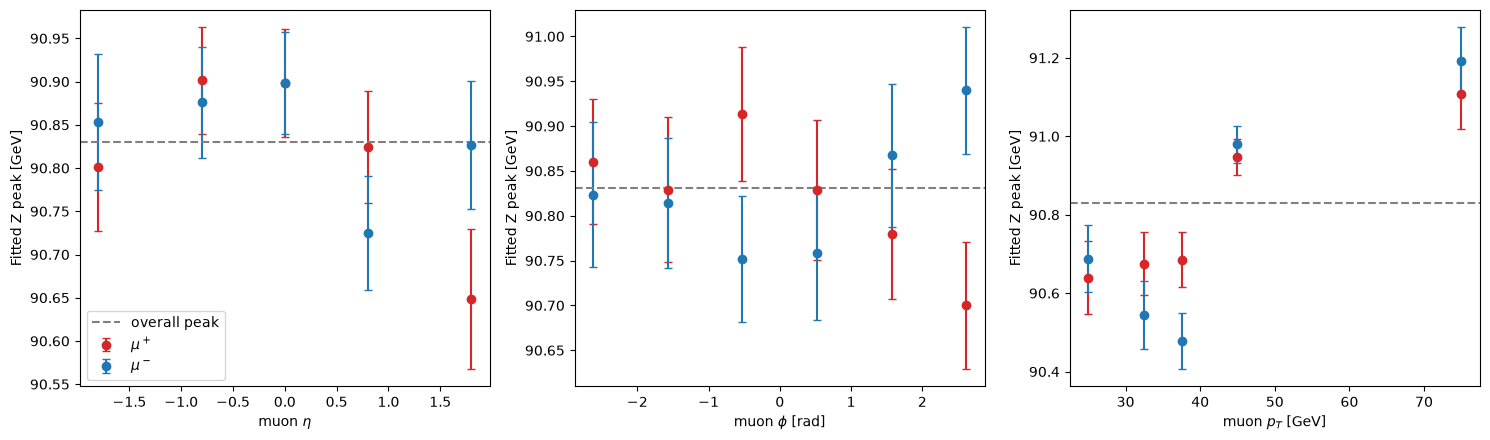

In [9]:
# %% 6. Plot: peak position vs eta, phi, pT for mu+ and mu-
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
labels = {"eta": r"muon $\eta$", "phi": r"muon $\phi$ [rad]", "pt": r"muon $p_T$ [GeV]"}
for ax, var in zip(axs, bins):
    for charge, colour, name in [("plus", "tab:red", r"$\mu^+$"), ("minus", "tab:blue", r"$\mu^-$")]:
        c, y, e = results[(var, charge)]
        ax.errorbar(c, y, yerr=e, fmt="o", color=colour, label=name, capsize=3)
    ax.axhline(all_peak, color="gray", ls="--", label="overall peak")
    ax.set_xlabel(labels[var]); ax.set_ylabel("Fitted Z peak [GeV]")
axs[0].legend()
fig.tight_layout(); fig.savefig("peak_vs_variables.png", dpi=200)

In [10]:
# %% 7. Simple correction test with cross-validation
# Split events into two random halves: derive the correction on A, test it on B.
# Correction: one mass scale factor per detector region of the pair, so that the
# peak matches the overall peak position. Regions use the larger |eta| of the two muons.
rng = np.random.default_rng(1)
is_A = rng.random(len(df)) < 0.5
df["region"] = np.where(np.maximum(abs(df.eta1), abs(df.eta2)) < 1.2, "barrel (|eta|<1.2)", "endcap-containing")

A, B = df[is_A], df[~is_A]
ref_peak, _ = fit_peak(A.mass)           # reference: overall peak position in half A
scale = {}
for region in df.region.unique():
    peak_A, _ = fit_peak(A.mass[A.region == region])
    scale[region] = ref_peak / peak_A    # factor that moves this region's peak onto the reference
print("\nScale factors derived on half A:", {k: round(v, 4) for k, v in scale.items()})

print("\nTest on half B (peak position, GeV):")
for region in df.region.unique():
    m = B.mass[B.region == region]
    before, err = fit_peak(m)
    after, _ = fit_peak(m * scale[region])
    print(f"  {region:20s} before {before:.3f} +/- {err:.3f}   after {after:.3f}")
spread_before = np.std([fit_peak(B.mass[B.region == r])[0] for r in df.region.unique()])
spread_after = np.std([fit_peak(B.mass[B.region == r] * scale[r])[0] for r in df.region.unique()])
print(f"  spread between regions: before {spread_before:.3f} GeV, after {spread_after:.3f} GeV")


Scale factors derived on half A: {'barrel (|eta|<1.2)': np.float64(0.9993), 'endcap-containing': np.float64(1.0006)}

Test on half B (peak position, GeV):
  barrel (|eta|<1.2)   before 90.849 +/- 0.060   after 90.748
  endcap-containing    before 90.736 +/- 0.059   after 90.775
  spread between regions: before 0.056 GeV, after 0.013 GeV
